## Importación de librerias

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Sección 1: Carga e inspección inicial con `pandas`

In [4]:
# 1. Cargar el dataset en un DataFrame
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# 2. Inspeccionar las primeras y últimas 5 filas
print("--- PRIMERAS 5 FILAS ---")
display(df.head())

print("\n--- ÚLTIMAS 5 FILAS ---")
display(df.tail())

# 3. Información general del DataFrame (registros, columnas, tipos de datos)
print("\n--- INFORMACIÓN GENERAL ---")
df.info()

# 4. Resumen estadístico de las variables numéricas
print("\n--- RESUMEN ESTADÍSTICO ---")
display(df.describe())

# 5. Detección de valores nulos en todo el dataset
print("\n--- VALORES NULOS POR COLUMNA ---")
print(df.isnull().sum())

--- PRIMERAS 5 FILAS ---


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



--- ÚLTIMAS 5 FILAS ---


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0



--- INFORMACIÓN GENERAL ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

--- RESUMEN ESTADÍSTICO ---


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000



--- VALORES NULOS POR COLUMNA ---
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


## Sección 2: Limpieza, transformación y tratamiento con `pandas` y `numpy`

In [5]:
# 1. Tratamiento de nulos: Imputar 'bmi' con la mediana
mediana_bmi = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(mediana_bmi)
print(f"Mediana utilizada para imputar BMI: {mediana_bmi:.2f}")
print(f"Nulos restantes en BMI: {df['bmi'].isnull().sum()}\n")

# 2. Detección de valores atípicos (Outliers) con el método IQR en variables continuas
variables_continuas = ['avg_glucose_level', 'bmi']

print("--- ANÁLISIS DE OUTLIERS (MÉTODO IQR) ---")
for col in variables_continuas:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - (1.5 * IQR)
    limite_superior = Q3 + (1.5 * IQR)

    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]

    print(f"Variable: '{col}'")
    print(f"  Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"  Límite inferior: {limite_inferior:.2f} | Límite superior: {limite_superior:.2f}")
    print(f"  Outliers detectados: {len(outliers)} (Rango real: {df[col].min():.2f} a {df[col].max():.2f})\n")

# 3. Eliminar la columna 'id' (no aporta valor predictivo)
df_limpio = df.drop(columns=['id'])

# 4. Codificación de variables categóricas (One-Hot Encoding)
# drop_first=True evita la multicolinealidad (trampa de las variables ficticias)
columnas_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_codificado = pd.get_dummies(df_limpio, columns=columnas_categoricas, drop_first=True, dtype=int)

print("--- DATASET TRANSFORMADO (PRIMERAS 5 FILAS) ---")
display(df_codificado.head())
print(f"Nuevas dimensiones del dataset: {df_codificado.shape}")

Mediana utilizada para imputar BMI: 28.10
Nulos restantes en BMI: 0

--- ANÁLISIS DE OUTLIERS (MÉTODO IQR) ---
Variable: 'avg_glucose_level'
  Q1: 77.25 | Q3: 114.09 | IQR: 36.84
  Límite inferior: 21.98 | Límite superior: 169.36
  Outliers detectados: 627 (Rango real: 55.12 a 271.74)

Variable: 'bmi'
  Q1: 23.80 | Q3: 32.80 | IQR: 9.00
  Límite inferior: 10.30 | Límite superior: 46.30
  Outliers detectados: 126 (Rango real: 10.30 a 97.60)

--- DATASET TRANSFORMADO (PRIMERAS 5 FILAS) ---


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,0,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,28.1,1,0,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,0,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,0,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1,0,0,1,0,0,1,0,0,0,1,0


Nuevas dimensiones del dataset: (5110, 17)


## Sección 3: Análisis visual y exploratorio con `matplotlib`

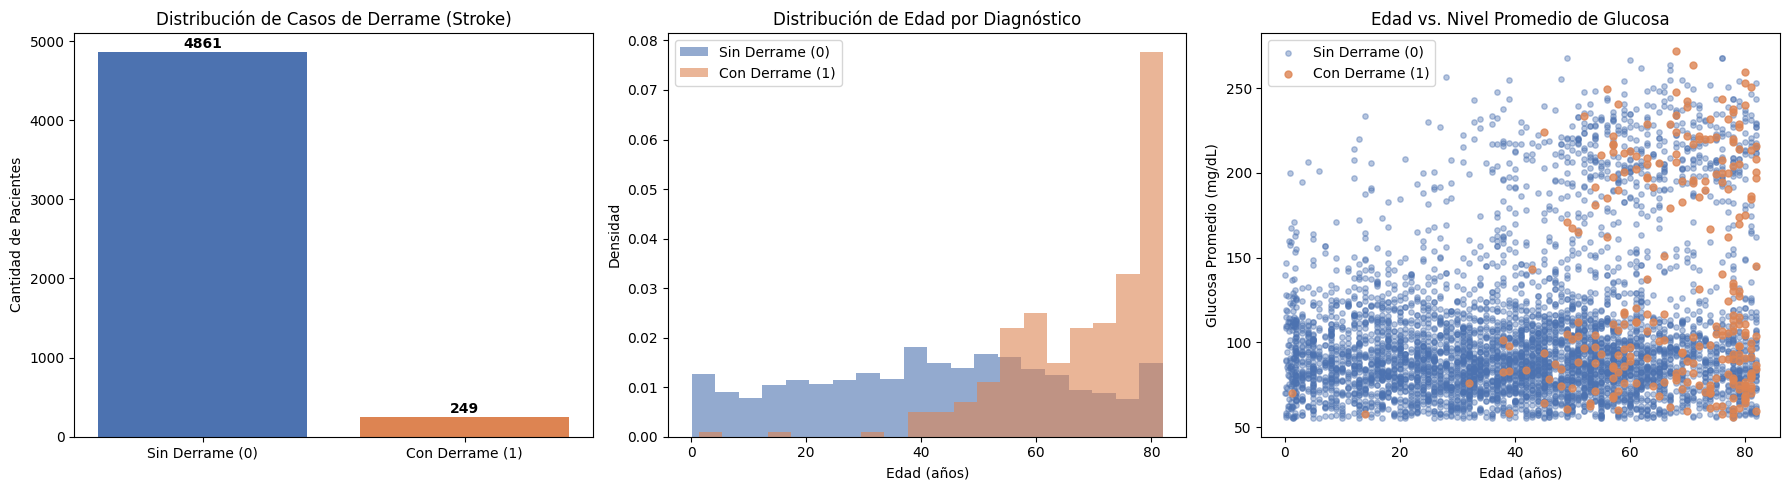

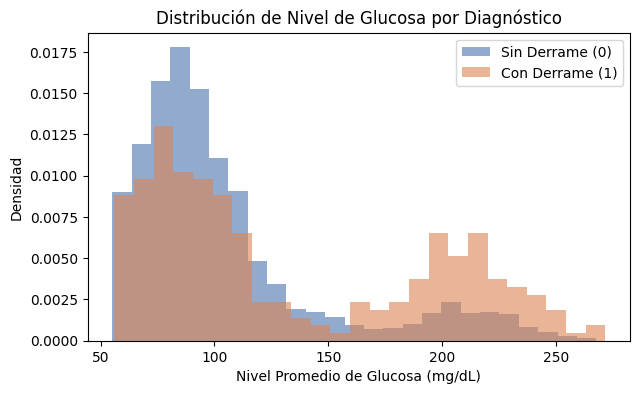

In [6]:
# Separar los grupos para facilitar la comparación visual
sin_stroke = df[df['stroke'] == 0]
con_stroke = df[df['stroke'] == 1]

# Configuración general de figura con 3 subgráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribución de la variable objetivo (Gráfico de barras)
conteo_stroke = df['stroke'].value_counts()
axes[0].bar(['Sin Derrame (0)', 'Con Derrame (1)'], conteo_stroke.values, color=['#4C72B0', '#DD8452'])
axes[0].set_title('Distribución de Casos de Derrame (Stroke)')
axes[0].set_ylabel('Cantidad de Pacientes')
for i, v in enumerate(conteo_stroke.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# 2. Histogramas comparativos (Edad)
# Usamos density=True para comparar proporciones debido al fuerte desbalance de clases
axes[1].hist(sin_stroke['age'], bins=20, alpha=0.6, label='Sin Derrame (0)', color='#4C72B0', density=True)
axes[1].hist(con_stroke['age'], bins=20, alpha=0.6, label='Con Derrame (1)', color='#DD8452', density=True)
axes[1].set_title('Distribución de Edad por Diagnóstico')
axes[1].set_xlabel('Edad (años)')
axes[1].set_ylabel('Densidad')
axes[1].legend()

# 3. Diagrama de dispersión (Edad vs. Nivel de Glucosa)
axes[2].scatter(sin_stroke['age'], sin_stroke['avg_glucose_level'], alpha=0.4, label='Sin Derrame (0)', color='#4C72B0', s=15)
axes[2].scatter(con_stroke['age'], con_stroke['avg_glucose_level'], alpha=0.8, label='Con Derrame (1)', color='#DD8452', s=25)
axes[2].set_title('Edad vs. Nivel Promedio de Glucosa')
axes[2].set_xlabel('Edad (años)')
axes[2].set_ylabel('Glucosa Promedio (mg/dL)')
axes[2].legend()

plt.tight_layout()
plt.show()

# Histograma adicional exclusivo para el nivel de glucosa
plt.figure(figsize=(7, 4))
plt.hist(sin_stroke['avg_glucose_level'], bins=25, alpha=0.6, label='Sin Derrame (0)', color='#4C72B0', density=True)
plt.hist(con_stroke['avg_glucose_level'], bins=25, alpha=0.6, label='Con Derrame (1)', color='#DD8452', density=True)
plt.title('Distribución de Nivel de Glucosa por Diagnóstico')
plt.xlabel('Nivel Promedio de Glucosa (mg/dL)')
plt.ylabel('Densidad')
plt.legend()
plt.show()

### Exportación del dataset limpio

In [7]:
df_codificado.to_csv('healthcare-dataset-stroke-data-limpio.csv', index=False)